# 05. Правило таргетинга и экономика
Клиенты делятся на 12 ячеек: частота покупок × возраст. Правило выбирается на одной случайной половине клиентов (A), а проверяется на другой (B), чтобы результат не был подогнан под данные.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

seg = pd.read_csv('data/segments.csv')
seg = seg[seg['age_group'] != 'нет данных']   # 0,4% клиентов с невозможным возрастом
seg['cell'] = seg['freq_group'] + ' | ' + seg['age_group']
seg = seg.sort_values('client_id').reset_index(drop=True)   # фиксированный порядок строк

# случайно делим клиентов на две половины
rng = np.random.default_rng(42)
seg['half'] = np.where(rng.random(len(seg)) < 0.5, 'A', 'B')
print(seg['half'].value_counts())

half
B    99624
A    99532
Name: count, dtype: int64


In [2]:
def cell_table(d):
    # эффект SMS и средний чек в каждой ячейке
    rows = []
    for cell in sorted(d['cell'].unique()):
        c = d[d['cell'] == cell]
        sms = c[c['treatment_flg'] == 1]['target']
        no_sms = c[c['treatment_flg'] == 0]['target']
        rows.append({
            'cell': cell,
            'клиентов': len(c),
            'эффект': sms.mean() - no_sms.mean(),
            'средний чек': c['avg_check'].mean(),
        })
    return pd.DataFrame(rows).set_index('cell')


A = cell_table(seg[seg['half'] == 'A'])
B = cell_table(seg[seg['half'] == 'B'])

# правило: слать SMS только в ячейки, где эффект на половине A выше среднего
avg_A = (A['эффект'] * A['клиентов']).sum() / A['клиентов'].sum()
target_cells = A[A['эффект'] > avg_A].index.tolist()

print(f'Средний эффект на половине A: +{avg_A * 100:.2f} п.п.')
print('SMS отправляем в ячейки:')
for cell in target_cells:
    print('   ', cell)

(A.sort_values('эффект', ascending=False)['эффект'] * 100).round(2)

Средний эффект на половине A: +3.20 п.п.
SMS отправляем в ячейки:
    1. редко | 1. 14–30
    1. редко | 2. 31–45
    1. редко | 3. 46–60
    1. редко | 4. 61+
    2. средне | 3. 46–60
    2. средне | 4. 61+


cell
1. редко | 4. 61+       7.18
2. средне | 4. 61+      5.22
1. редко | 2. 31–45     4.54
2. средне | 3. 46–60    4.42
1. редко | 3. 46–60     4.15
1. редко | 1. 14–30     3.38
3. часто | 4. 61+       1.97
3. часто | 1. 14–30     1.90
3. часто | 2. 31–45     1.82
3. часто | 3. 46–60     1.73
2. средне | 2. 31–45    1.53
2. средне | 1. 14–30    0.75
Name: эффект, dtype: float64

## Проверка правила на половине B

In [3]:
B['в правиле'] = B.index.isin(target_cells)
B['доп. покупатели'] = B['эффект'] * B['клиентов']

inside = B[B['в правиле']]
outside = B[~B['в правиле']]

share_clients = inside['клиентов'].sum() / B['клиентов'].sum()
share_effect = inside['доп. покупатели'].sum() / B['доп. покупатели'].sum()
effect_inside = inside['доп. покупатели'].sum() / inside['клиентов'].sum()
effect_outside = outside['доп. покупатели'].sum() / outside['клиентов'].sum()

print(f'SMS получают {share_clients:.0%} клиентов')
print(f'Они дают {share_effect:.0%} всех дополнительных покупок от рассылки')
print(f'Эффект SMS в правиле: +{effect_inside * 100:.2f} п.п., вне правила: +{effect_outside * 100:.2f} п.п.')
print(f'Дополнительных покупателей на 100 SMS: {effect_inside * 100:.1f} в правиле против {effect_outside * 100:.1f} вне его')

SMS получают 50% клиентов
Они дают 73% всех дополнительных покупок от рассылки
Эффект SMS в правиле: +4.60 п.п., вне правила: +1.70 п.п.
Дополнительных покупателей на 100 SMS: 4.6 в правиле против 1.7 вне его


## Экономика
В данных нет стоимости SMS и маржи, поэтому это допущения. Доход с одного дополнительного покупателя = средний чек ячейки × маржа. Расчёт на 100 тыс. клиентов.

In [4]:
SMS_COST = 2     # руб. за одну SMS (допущение)
MARGIN = 0.20    # маржа с покупки (допущение)


def profit(table, cells, sms_cost, margin):
    t = table.loc[cells]
    income = (t['эффект'] * t['клиентов'] * t['средний чек'] * margin).sum()
    cost = t['клиентов'].sum() * sms_cost
    return income - cost


all_cells = B.index.tolist()
scale = 100000 / B['клиентов'].sum()   # пересчёт на 100 тыс. клиентов

profit_all = profit(B, all_cells, SMS_COST, MARGIN) * scale
profit_rule = profit(B, target_cells, SMS_COST, MARGIN) * scale

print(f'Рассылка всем:      {profit_all:,.0f} руб.')
print(f'Рассылка по правилу: {profit_rule:,.0f} руб.')
print(f'SMS отправлено: 100 000 против {share_clients * 100000:,.0f}')

Рассылка всем:      124,025 руб.
Рассылка по правилу: 147,780 руб.
SMS отправлено: 100 000 против 50,226


## Чувствительность к допущениям
Как меняется результат при другой стоимости SMS и марже.

In [5]:
rows = []
for sms_cost in [1, 2, 3, 5]:
    for margin in [0.10, 0.20, 0.30]:
        p_all = profit(B, all_cells, sms_cost, margin) * scale
        p_rule = profit(B, target_cells, sms_cost, margin) * scale
        rows.append({
            'SMS, руб.': sms_cost,
            'маржа, %': int(margin * 100),
            'всем, руб.': p_all,
            'по правилу, руб.': p_rule,
            'разница, руб.': p_rule - p_all,
        })

sens = pd.DataFrame(rows)
sens.round(0).astype(int)

,"SMS, руб.","маржа, %","всем, руб.","по правилу, руб.","разница, руб."
0,1,10,62012,73890,11877
1,1,20,224025,198006,-26019
2,1,30,386037,322121,-63916
3,2,10,-37988,23664,61652
4,2,20,124025,147780,23755
5,2,30,286037,271895,-14142
6,3,10,-137988,-26562,111426
7,3,20,24025,97554,73529
8,3,30,186037,221670,35632
9,5,10,-337988,-127014,210974


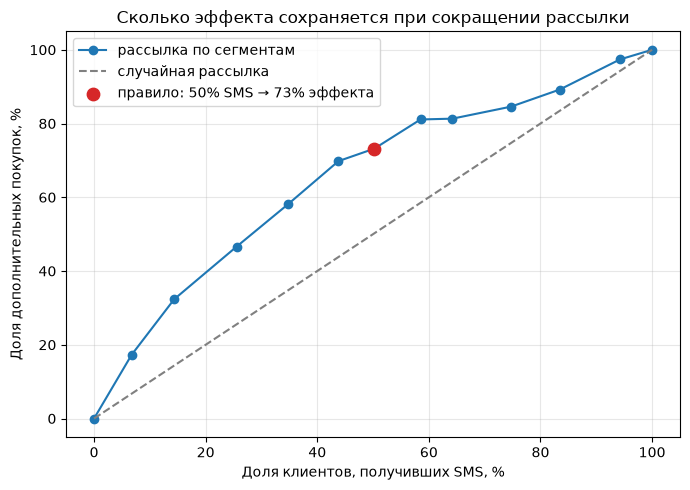

In [6]:
os.makedirs('images', exist_ok=True)

# ячейки по убыванию эффекта на A, накопленный результат на B
order = A.sort_values('эффект', ascending=False).index
curve = B.loc[order]
x = [0] + list(curve['клиентов'].cumsum() / curve['клиентов'].sum() * 100)
y = [0] + list(curve['доп. покупатели'].cumsum() / curve['доп. покупатели'].sum() * 100)

plt.figure(figsize=(7, 5))
plt.plot(x, y, marker='o', label='рассылка по сегментам')
plt.plot([0, 100], [0, 100], linestyle='--', color='gray', label='случайная рассылка')
plt.scatter([share_clients * 100], [share_effect * 100], color='tab:red', s=80, zorder=3,
            label=f'правило: {share_clients:.0%} SMS → {share_effect:.0%} эффекта')
plt.xlabel('Доля клиентов, получивших SMS, %')
plt.ylabel('Доля дополнительных покупок, %')
plt.title('Сколько эффекта сохраняется при сокращении рассылки')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('images/targeting_curve.png', dpi=150)
plt.show()

**Итог:**
- Правило: SMS только редким покупателям (любой возраст) и клиентам со средней частотой покупок от 46 лет.
- Проверка на половине B: 50% SMS дают 73% дополнительных покупок. Эффект +4,6 п.п. в правиле против +1,7 п.п. вне его.
- Другая половина SMS даёт только 27% эффекта.
- При SMS 2 руб. и марже 20% правило выгоднее рассылки всем примерно на 24 тыс. руб. на каждые 100 тыс. клиентов. Рассылка всем выигрывает только при очень дешёвой SMS (1 руб.) или высокой марже (30%).
- Ограничения: доход с покупки оценён по среднему чеку до рассылки; стоимость скидки из SMS в данных неизвестна.